## Evoluzione delle anime negli anni

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from solution.utils import utils

In [2]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")
df_character_nicknames = pd.read_csv("../../dataset/cleaned/character_nicknames_cleaned.csv")

In [3]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")
df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")

## 1. La crescita storica della produzione anime

### Come si è evoluta la produzione di anime nel tempo?

In [4]:
details = df_details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Dagli anni ’70 in poi si osserva una **crescita** quasi **esponenziale** del numero di anime prodotti, con un’accelerazione marcata dopo il 2000.
Negli ultimi anni, invece, il trend mostra oscillazioni e un leggero **calo**, suggerendo una possibile fase di saturazione del mercato.

### Quali generi dominano ----- anime ?

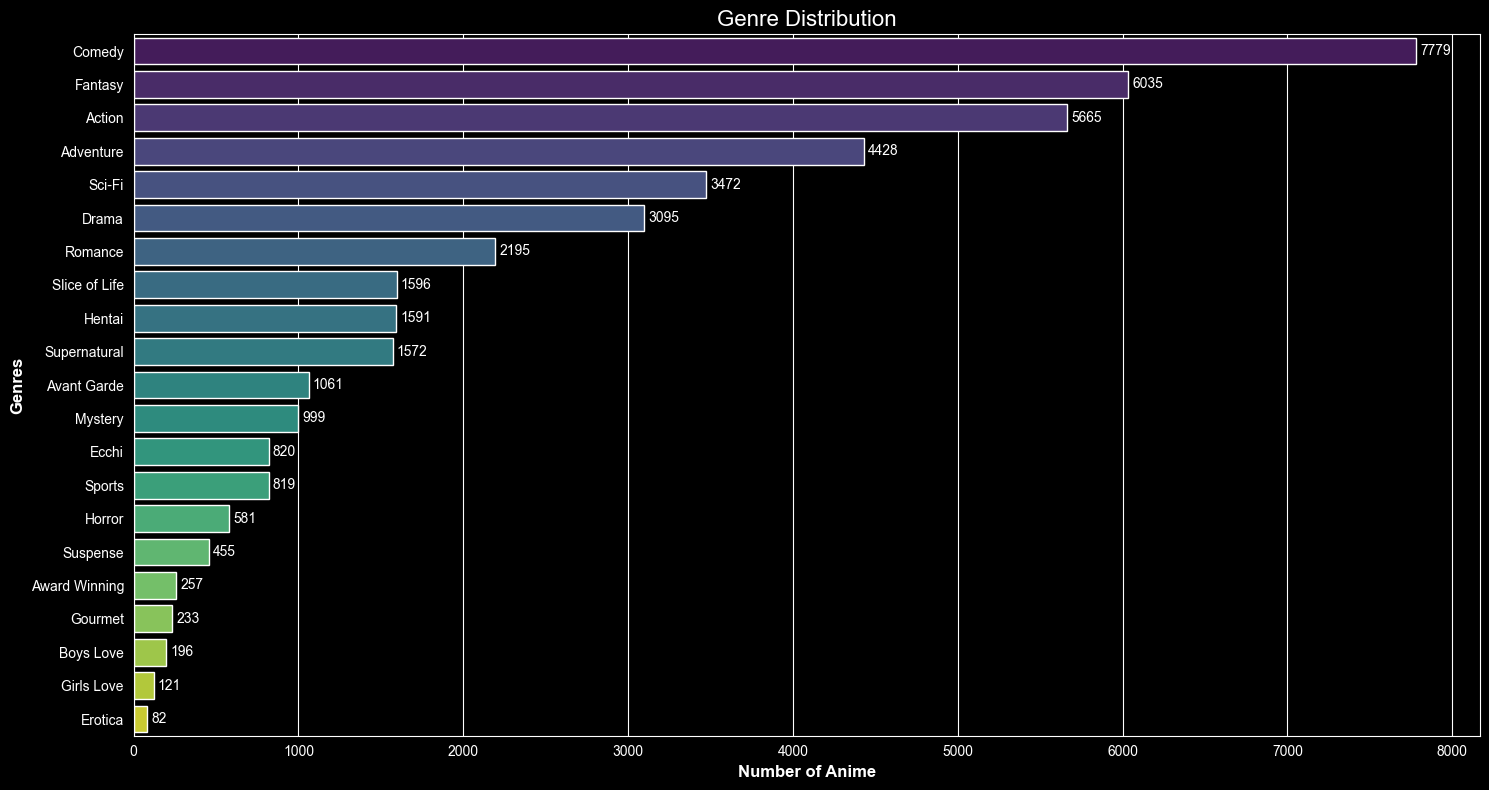

In [5]:
df_genres = df_details['genres'].copy()
df_genres = df_genres.apply(ast.literal_eval)

df_genres = df_genres.explode().dropna()
genre_count = df_genres.value_counts().reset_index()

genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


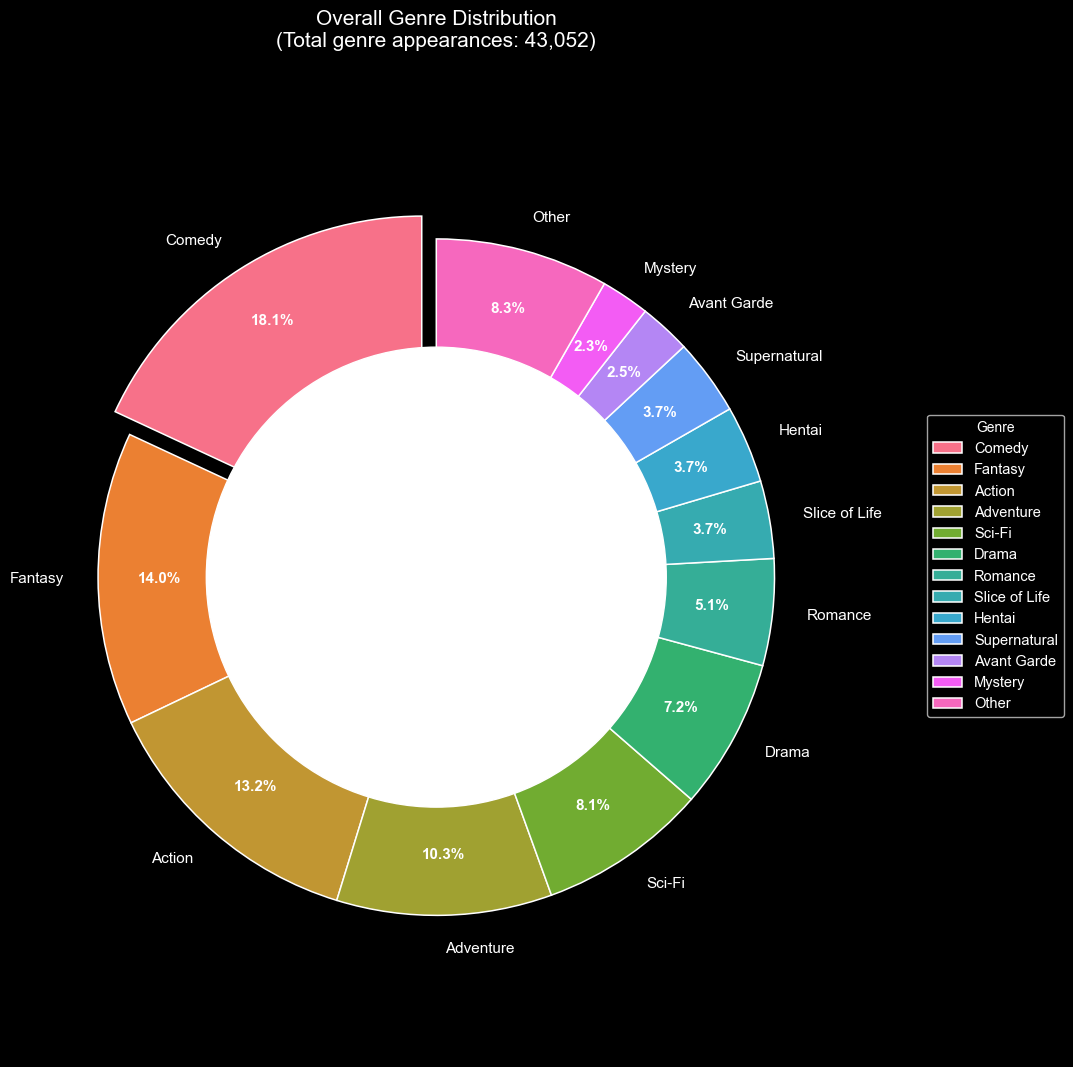

In [6]:
details = df_details.copy()
details = details.dropna(subset=['genres'])
details['genres'] = details['genres'].apply(utils.parse_genres)
# Explode: una riga per ogni genere
genres_df = details.explode('genres')
# Conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# Top 12 generi + Other
top_n_pie = 12
top_genres_pie = genre_total.head(top_n_pie)
other_count = genre_total.iloc[top_n_pie:].sum()

if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie

plt.figure(figsize=(11, 11))
colors = sns.color_palette("husl", len(pie_data))

# Explode solo sulla fetta più grande
explode = [0.08 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]

wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 11}
)

# Stile percentuali
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title(f"Overall Genre Distribution\n(Total genre appearances: {genre_total.sum():,})",fontsize=15, pad=20)
# Effetto donut
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Legenda
plt.legend(pie_data.index, title="Genre", loc="center left",bbox_to_anchor=(1.15, 0.5), fontsize=10.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

### Come sono cambiati i generi anime nel tempo?

In [7]:
df_gen_evol = df_details.copy()
df_gen_evol = df_gen_evol.dropna(subset=['year'])
df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
df_gen_evol['genres'] = df_gen_evol['genres'].apply(utils.parse_genres)
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])

# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible='legendonly'
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()

Questo grafico mostra l’evoluzione dei principali generi anime nel tempo, evidenziando come la crescita dell’industria sia stata accompagnata da una progressiva specializzazione dei contenuti.

Fino agli anni ’80 la produzione è limitata e relativamente omogenea, mentre a partire dagli anni ’90 emergono differenze sempre più marcate tra i generi.

Dopo il 2000 si osserva una forte espansione di generi come **Action**, **Fantasy** e **Comedy**, riflettendo l’ampliamento del pubblico e la diversificazione dei gusti.

Negli anni più recenti alcune curve mostrano una stabilizzazione o una lieve flessione, suggerendo una fase di assestamento del mercato più che una diminuzione di interesse

## 2. Dalla produzione alla valutazione degli utenti

### La qualità percepita degli anime è cambiata nel tempo?

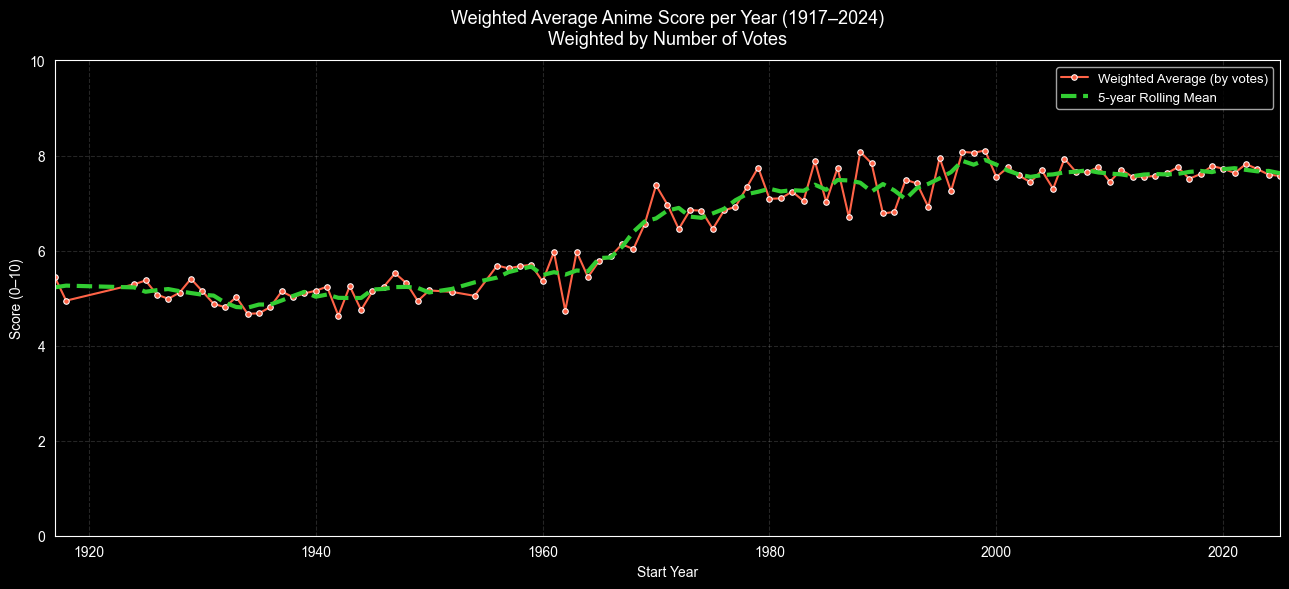

In [8]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()
# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]
# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='5-year Rolling Mean'
)
plt.title("Weighted Average Anime Score per Year (1917–2024)\nWeighted by Number of Votes",fontsize=13,pad=12)
plt.xlabel("Start Year")
plt.ylabel("Score (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.


### I generi più prodotti sono anche quelli più amati dai fan?

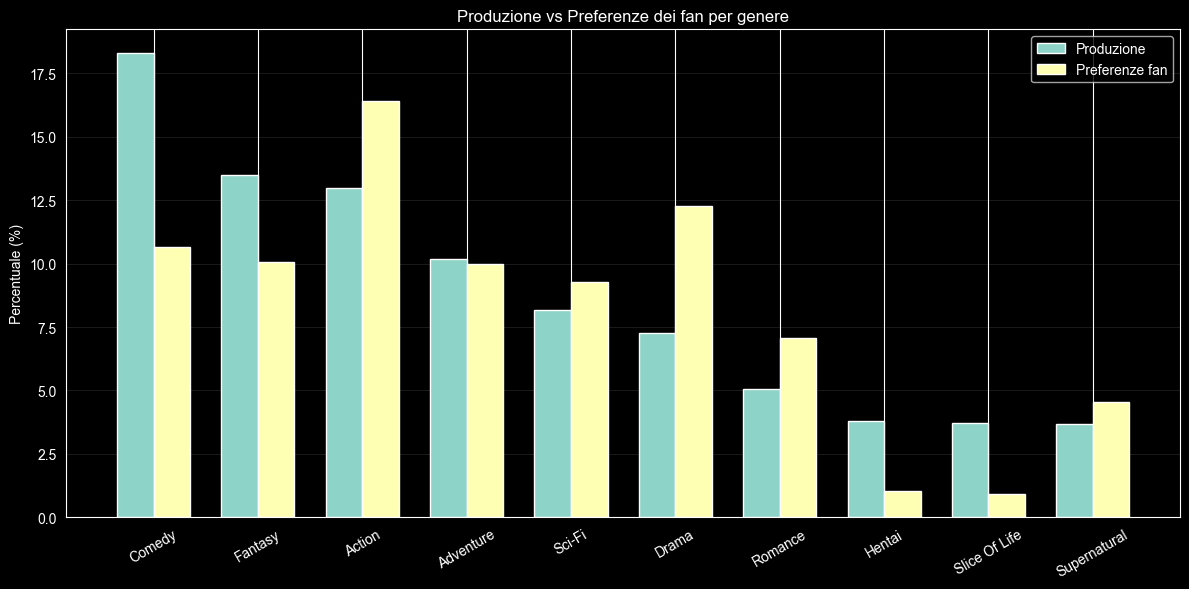

In [9]:
favs = df_favs.copy()
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(axis='y', alpha=0.1)
plt.tight_layout()
plt.show()

Il confronto tra la quota di produzione e le preferenze dei fan evidenzia come le strategie dell’industria anime non siano sempre allineate con i gusti del pubblico.
Mentre generi come Action mostrano un equilibrio tra offerta e domanda, altri come Comedy risultano sovra-rappresentati.
Al contrario, generi come Drama e Romance sembrano essere sottovalutati dall’industria nonostante un forte interesse da parte dei fan.

## 3. Da dove nascono le storie degli anime?

### Da dove nascono -----

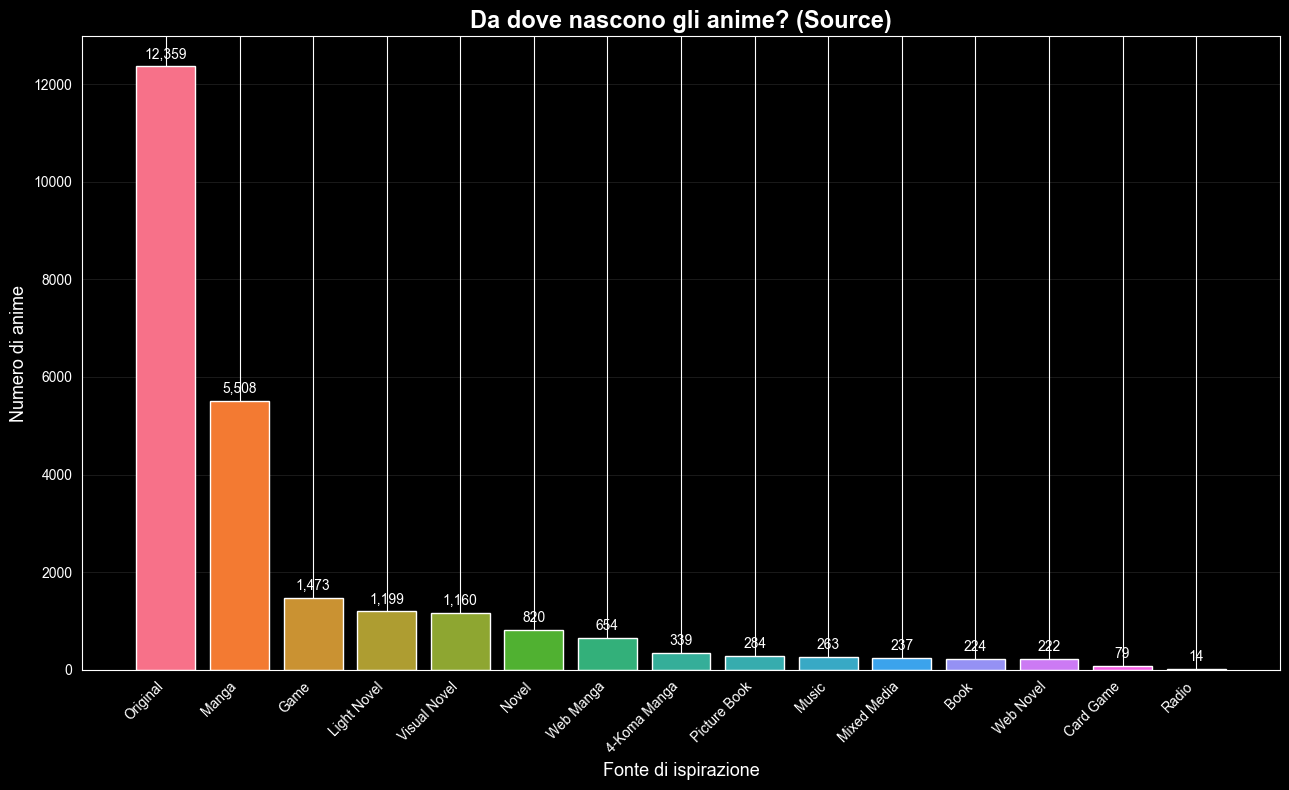

In [10]:
details = df_details.copy()
# filtro categoria unknown
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
details['source'] = details['source'].str.strip().str.title()
source_counts = (details['source'].value_counts().reset_index())
source_counts.columns = ['source', 'count']
# grafico
plt.figure(figsize=(13, 8))

colors = sns.color_palette("husl", n_colors=len(source_counts))

bars = plt.bar(source_counts['source'], source_counts['count'], color=colors)

# Aggiunge i numeri sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 100,
             f'{int(height):,}', ha='center', va='bottom', fontsize=10)

plt.xlabel("Fonte di ispirazione", fontsize=13)
plt.ylabel("Numero di anime", fontsize=13)
plt.title("Da dove nascono gli anime? (Source)", fontsize=17, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.1)

plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.


## 4. Popolarità e impatto culturale

### In quali anni emergono gli anime più popolari?

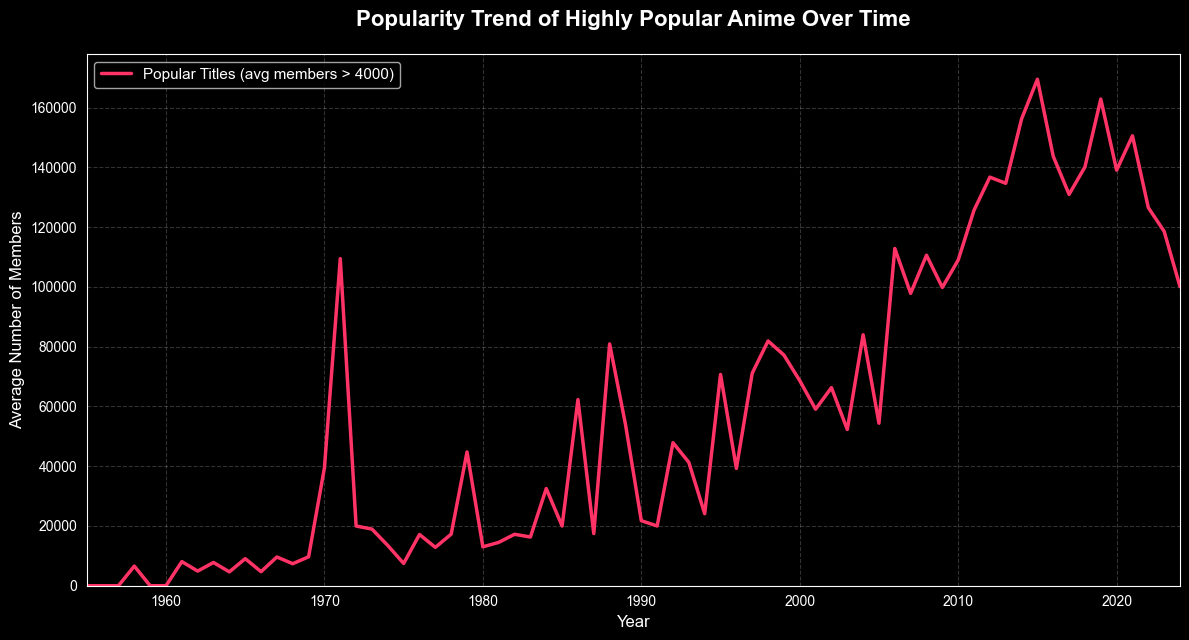

In [11]:
details = df_details.copy()

popular_pop = (details[details['members'] > 4000].groupby('year')['members'].mean().reindex(range(1955, 2025), fill_value=0).reset_index())

plt.figure(figsize=(12, 6.5))
plt.plot(
    popular_pop['year'],
    popular_pop['members'],
    color='#FF3366',
    linewidth=2.5,
    label='Popular Titles (avg members > 4000)'
)

plt.title('Popularity Trend of Highly Popular Anime Over Time',
          fontsize=16,
          fontweight='bold',
          pad=20)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Number of Members', fontsize=12)
plt.grid(True, alpha=0.2, linestyle='--')
plt.legend(fontsize=11, loc='upper left')
plt.xlim(1955, 2024)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

### ------- top anime

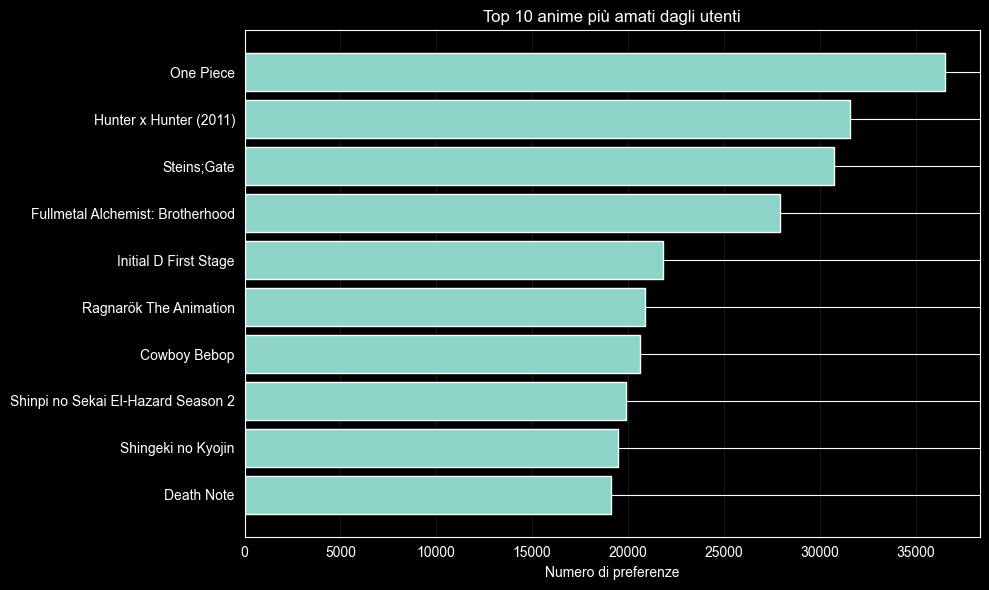

In [12]:
details = df_details.copy()
favs = df_favs.copy()
valid_mal_ids = details['mal_id'].unique()
filtered_favs = favs[favs['mal_id'].isin(valid_mal_ids)]
top_anime = (filtered_favs['mal_id'].value_counts().head(10).reset_index())
top_anime.columns = ['mal_id', 'fav_count']
top_anime = pd.merge(top_anime, details[['mal_id', 'title']], on='mal_id', how='inner')
# Sort for horizontal bar chart
top_anime = top_anime.sort_values('fav_count')
plt.figure(figsize=(10, 6))
plt.barh(top_anime['title'], top_anime['fav_count'])
plt.xlabel("Numero di preferenze")
plt.title("Top 10 anime più amati dagli utenti")
plt.grid(axis='x', alpha=0.1)

plt.tight_layout()
plt.show()

### One Piece: qualità percepita e popolarità tra gli utenti


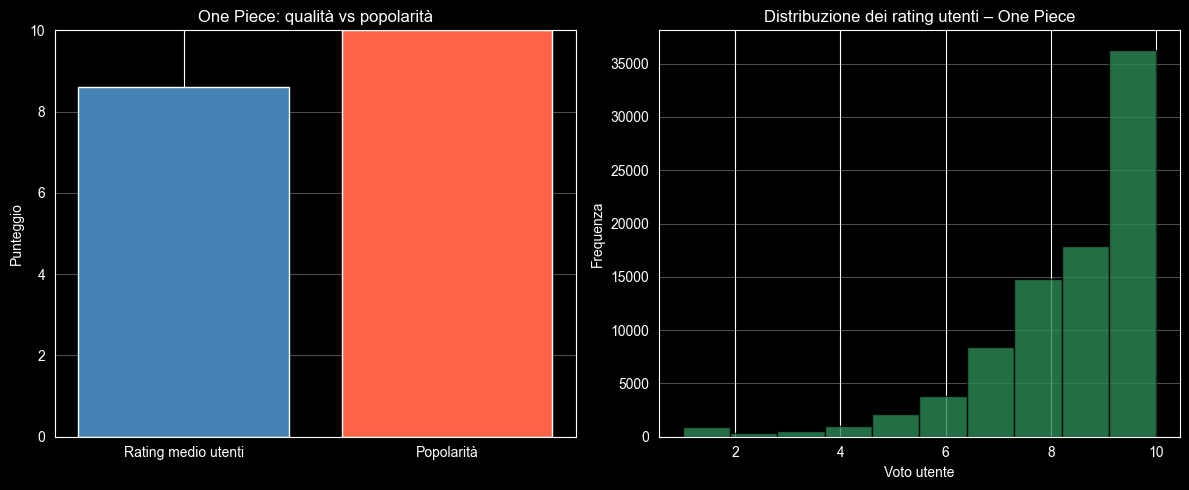

In [13]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = "One Piece"
anime_row = details[details["title"] == anime_title]
mal_id = anime_row["mal_id"].iloc[0]
# Rimuoviamo score = 0 (utenti che non hanno votato)
anime_ratings = ratings[(ratings["anime_id"] == mal_id) & (ratings["score"] > 0)]["score"]
avg_user_rating = anime_ratings.mean()
fav_count = favs[favs["mal_id"] == mal_id].shape[0]
# Normalizzazione favs su scala 0–10
fav_score_norm = (fav_count / favs["mal_id"].value_counts().max()) * 10
# Grafici
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Qualità vs Popolarità
labels = ["Rating medio utenti", "Popolarità"]
values = [avg_user_rating, fav_score_norm]
axes[0].bar(labels, values, color=["steelblue", "tomato"])
axes[0].set_ylim(0, 10)
axes[0].set_ylabel("Punteggio")
axes[0].set_title("One Piece: qualità vs popolarità")
axes[0].grid(axis="y", alpha=0.3)
# Distribuzione rating utenti
axes[1].hist(
    anime_ratings,
    bins=10,
    color="seagreen",
    edgecolor="black",
    alpha=0.8
)
axes[1].set_xlabel("Voto utente")
axes[1].set_ylabel("Frequenza")
axes[1].set_title("Distribuzione dei rating utenti – One Piece")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


### Gli anime con il rating più basso: cosa non ha convinto il pubblico

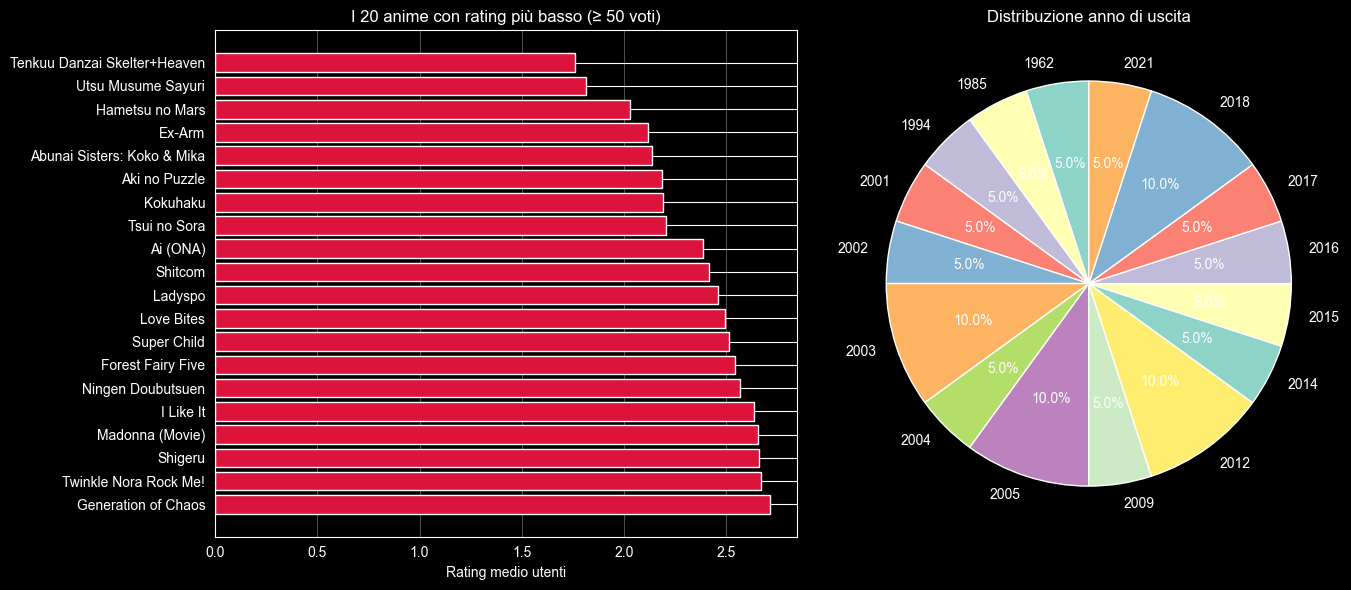

In [14]:
ratings_clean = df_ratings.copy()
ratings_clean = ratings_clean[ratings_clean["score"] > 0]
rating_stats = (ratings_clean.groupby("anime_id").agg(avg_user_score=("score", "mean"),num_votes=("score", "count")).reset_index())
# tieni solo anime con almeno 50 voti
rating_stats = rating_stats[rating_stats["num_votes"] >= 50]
anime_scores = pd.merge(
    rating_stats,
    df_details[["mal_id", "title", "year", "popularity"]],
    left_on="anime_id",
    right_on="mal_id",
    how="inner"
)
# filtro anno SENZA sovrascrivere tutto
anime_scores = anime_scores[(anime_scores["year"] >= 1917) & (anime_scores["year"] <= 2024)]
worst_20 = (anime_scores.sort_values("avg_user_score", ascending=True).head(20))
year_counts = worst_20["year"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh( worst_20["title"],worst_20["avg_user_score"],color="crimson")
axes[0].invert_yaxis()
axes[0].set_xlabel("Rating medio utenti")
axes[0].set_title("I 20 anime con rating più basso (≥ 50 voti)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].pie(
    year_counts.values,
    labels=year_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Distribuzione anno di uscita")

plt.tight_layout()
plt.show()

## 5. I personaggi come centro emotivo degli anime

### Personaggi secondari VS principali e la loro notorietà

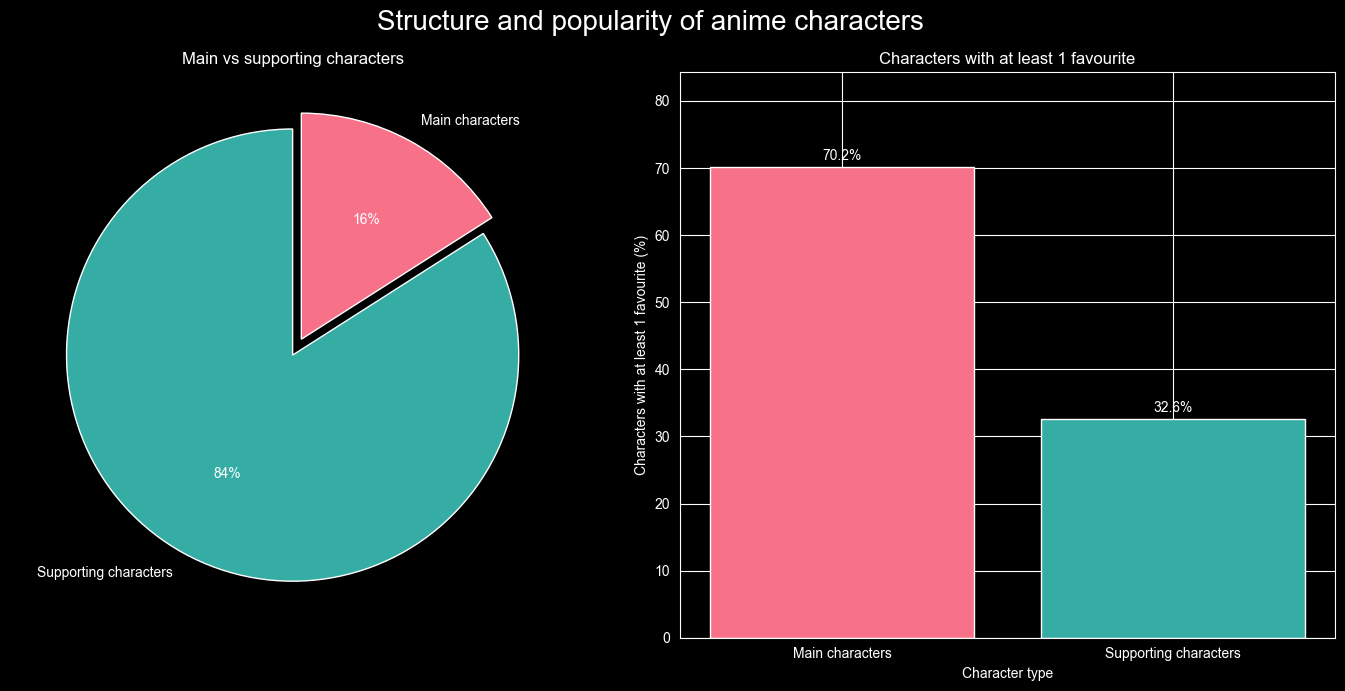

In [15]:
# preparazione dati
character_popularity = (
    df_characters_anime_works
    .loc[lambda df: df["role"].isin(["Main", "Supporting"]), ["character_mal_id", "role"]]
    .drop_duplicates()
    .groupby("character_mal_id")
    .filter(lambda x: x["role"].nunique() == 1)
    .drop_duplicates("character_mal_id")
    .rename(columns={"role": "role_group"})
    .merge(df_characters[["character_mal_id", "favorites"]], on="character_mal_id")
)
character_popularity["has_favorites"] = character_popularity["favorites"] > 0
main_support_table = (
    character_popularity.groupby("role_group")["character_mal_id"].nunique().reset_index(name="total_characters")
)
popularity_table = (
    character_popularity.groupby("role_group").agg(number_of_characters=("character_mal_id", "nunique"), characters_with_favourites=("has_favorites", "sum")
    ).assign(
        share_with_favourites=lambda df: (df["characters_with_favourites"] / df["number_of_characters"] * 100).round(1)
    ).reset_index()
)
mapping = {"Main": "Main characters", "Supporting": "Supporting characters"}
for df in [main_support_table, popularity_table]:
    df["role_group"] = pd.Categorical(df["role_group"].replace(mapping), categories=["Main characters", "Supporting characters"], ordered=True)
    df.sort_values("role_group", inplace=True)
# PLOT
#plt.style.use("default")
#sns.set_style("whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle("Structure and popularity of anime characters", fontsize=20)
colors = sns.color_palette("husl", 2)
# pie
ax[0].pie(
    main_support_table["total_characters"], labels=main_support_table["role_group"], autopct="%1.0f%%", startangle=90, counterclock=False, colors=colors, explode=[0.08, 0]
)
ax[0].set_title("Main vs supporting characters")
# bar
bars = ax[1].bar(
    popularity_table["role_group"], popularity_table["share_with_favourites"], color=colors
)
ax[1].bar_label(bars,
    labels=popularity_table["share_with_favourites"].astype(str) + "%", padding=3
)
ax[1].set(
    title="Characters with at least 1 favourite", xlabel="Character type", ylabel="Characters with at least 1 favourite (%)", ylim=(0, popularity_table["share_with_favourites"].max() * 1.2)
)
plt.tight_layout()
plt.show()

Questi due grafici mostrano la struttura e la popolarità dei personaggi negli anime. Il primo evidenzia che i personaggi secondari rappresentano la parte più ampia del cast complessivo, mentre i personaggi principali costituiscono una quota molto più ridotta. Il secondo grafico mostra però che, nonostante siano meno numerosi, i personaggi principali hanno una probabilità molto più alta di ricevere almeno un preferito dagli utenti. Nel complesso, l’analisi suggerisce che i personaggi secondari dominano sul piano quantitativo, ma i personaggi principali concentrano una parte molto maggiore dell’attenzione e del riconoscimento del pubblico.

## 6. I DOPPIATORI E LINGUE: le voci dietro gli anime

## Quanti doppiatori ha ciascuna anima nella top 10?

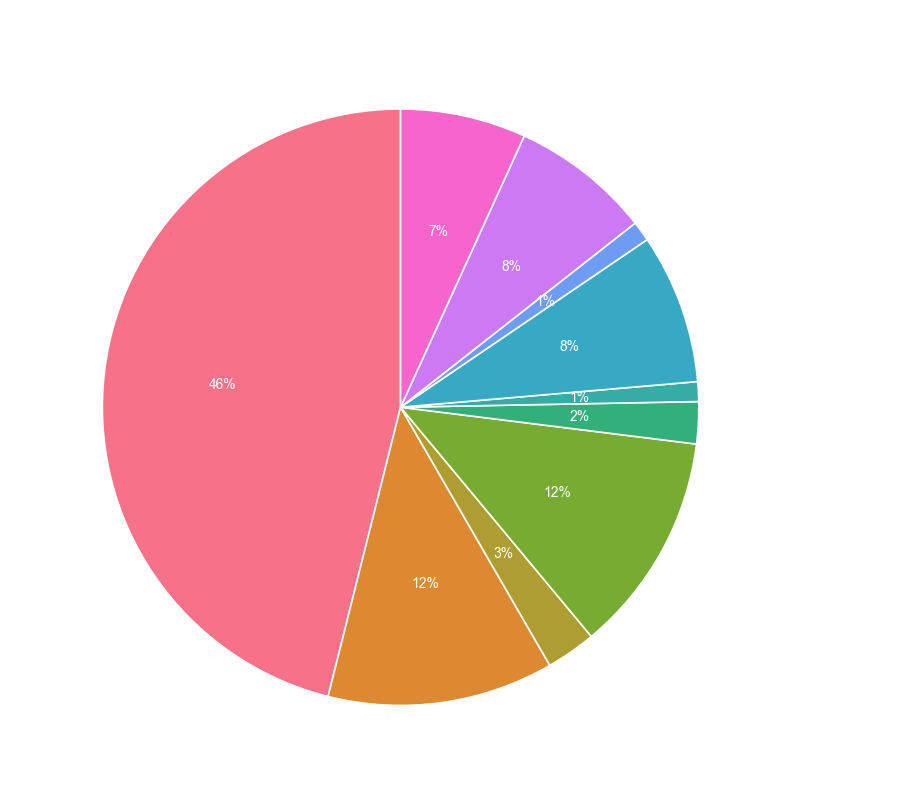

In [16]:
details = df_details.copy()
favs = df_favs.copy()
voice_works = df_person_voice_works.copy()

valid_mal_ids = details["mal_id"].unique()
filtered_favs = favs[favs["mal_id"].isin(valid_mal_ids)]

top_anime = filtered_favs["mal_id"].value_counts().head(10).reset_index()
top_anime.columns = ["mal_id", "fav_count"]

top_anime = pd.merge(top_anime, details[["mal_id", "title"]], on="mal_id", how="inner")

voice_actor_counts = (
    voice_works[voice_works["anime_mal_id"].isin(top_anime["mal_id"])]
    .groupby("anime_mal_id")["person_mal_id"]
    .nunique()
    .reset_index()
)
voice_actor_counts.columns = ["mal_id", "distinct_voice_actors"]

top_anime_voice = pd.merge(top_anime, voice_actor_counts, on="mal_id", how="left")
top_anime_voice["distinct_voice_actors"] = top_anime_voice["distinct_voice_actors"].fillna(0).astype(int)

palette = sns.color_palette("husl", len(top_anime_voice))
fig, ax = plt.subplots(figsize=(11, 8), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.pie(
    top_anime_voice["distinct_voice_actors"],
    labels=top_anime_voice["title"],
    autopct="%1.0f%%",
    startangle=90,
    colors=palette,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2}
)

ax.set_title("Voice actors in the top 10 most popular anime", fontsize=16)
plt.tight_layout()
plt.show()

Questo grafico mostra quanti doppiatori sono coinvolte per le top 10 anime più diffuse. Notiamo che One Piece emerge rispetto agli altri titoli, con un cast molto numeroso di doppiatori. Questo suggerisce che alcuni degli anime più apprezzati dagli utenti sono anche quelli caratterizzati da una struttura di doppiaggio più complessa e numerosa, mentre altri si basano su un insieme più ristretto di doppiatori.

## Top 10 doppiatori per personaggi distinti doppiati

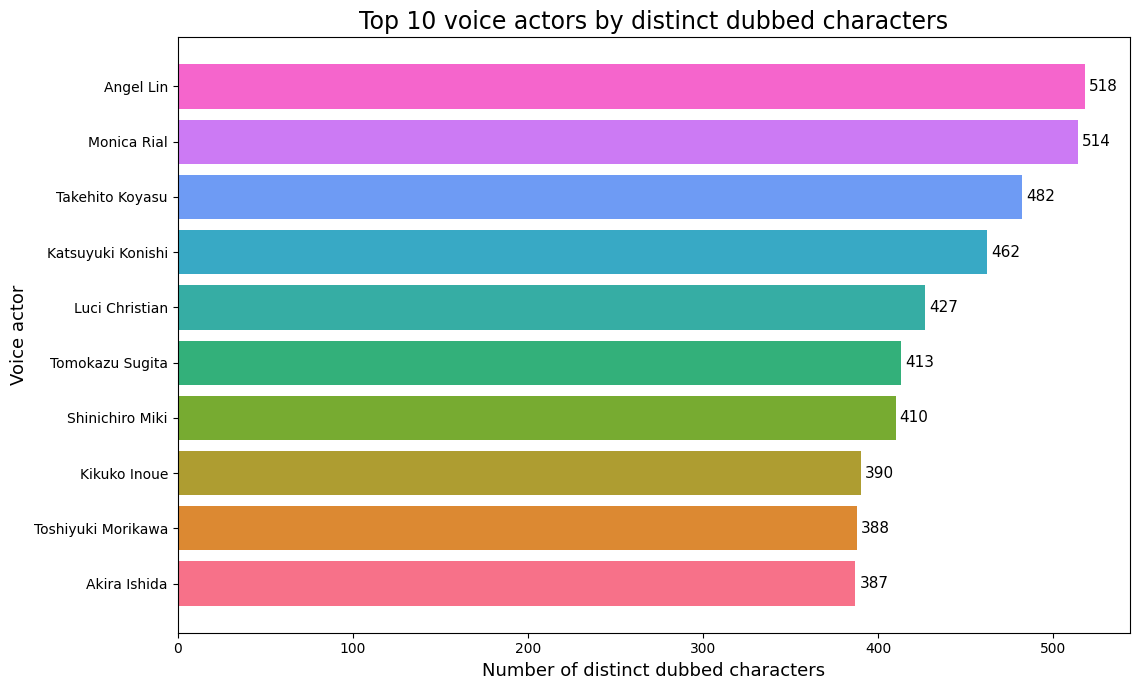

In [17]:
voice_works = df_person_voice_works.copy()
person_details = df_person_details.copy()

top_voice_actors = (
    voice_works.groupby("person_mal_id")["character_mal_id"].nunique().reset_index(name="distinct_dubbed_characters")
)
top_voice_actors = top_voice_actors.sort_values("distinct_dubbed_characters", ascending=False).head(10)
top_voice_actors = pd.merge(
    top_voice_actors, person_details[["person_mal_id", "name"]], on="person_mal_id", how="left"
)
top_voice_actors = top_voice_actors.sort_values("distinct_dubbed_characters", ascending=True)
palette = sns.color_palette("husl", len(top_voice_actors))
plt.style.use("default")

fig, ax = plt.subplots(figsize=(11.5, 7), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.barh(
    top_voice_actors["name"], top_voice_actors["distinct_dubbed_characters"], color=palette
)
ax.set_title("Top 10 voice actors by distinct dubbed characters", fontsize=17)
ax.set_xlabel("Number of distinct dubbed characters", fontsize=13)
ax.set_ylabel("Voice actor", fontsize=13)

ax.bar_label(bars, padding=3, fontsize=11)
plt.tight_layout()
plt.show()

Questo grafico ci permette di individuare i doppiatori più versatili e presenti all’interno dell’industria anime rappresentata nei dati.

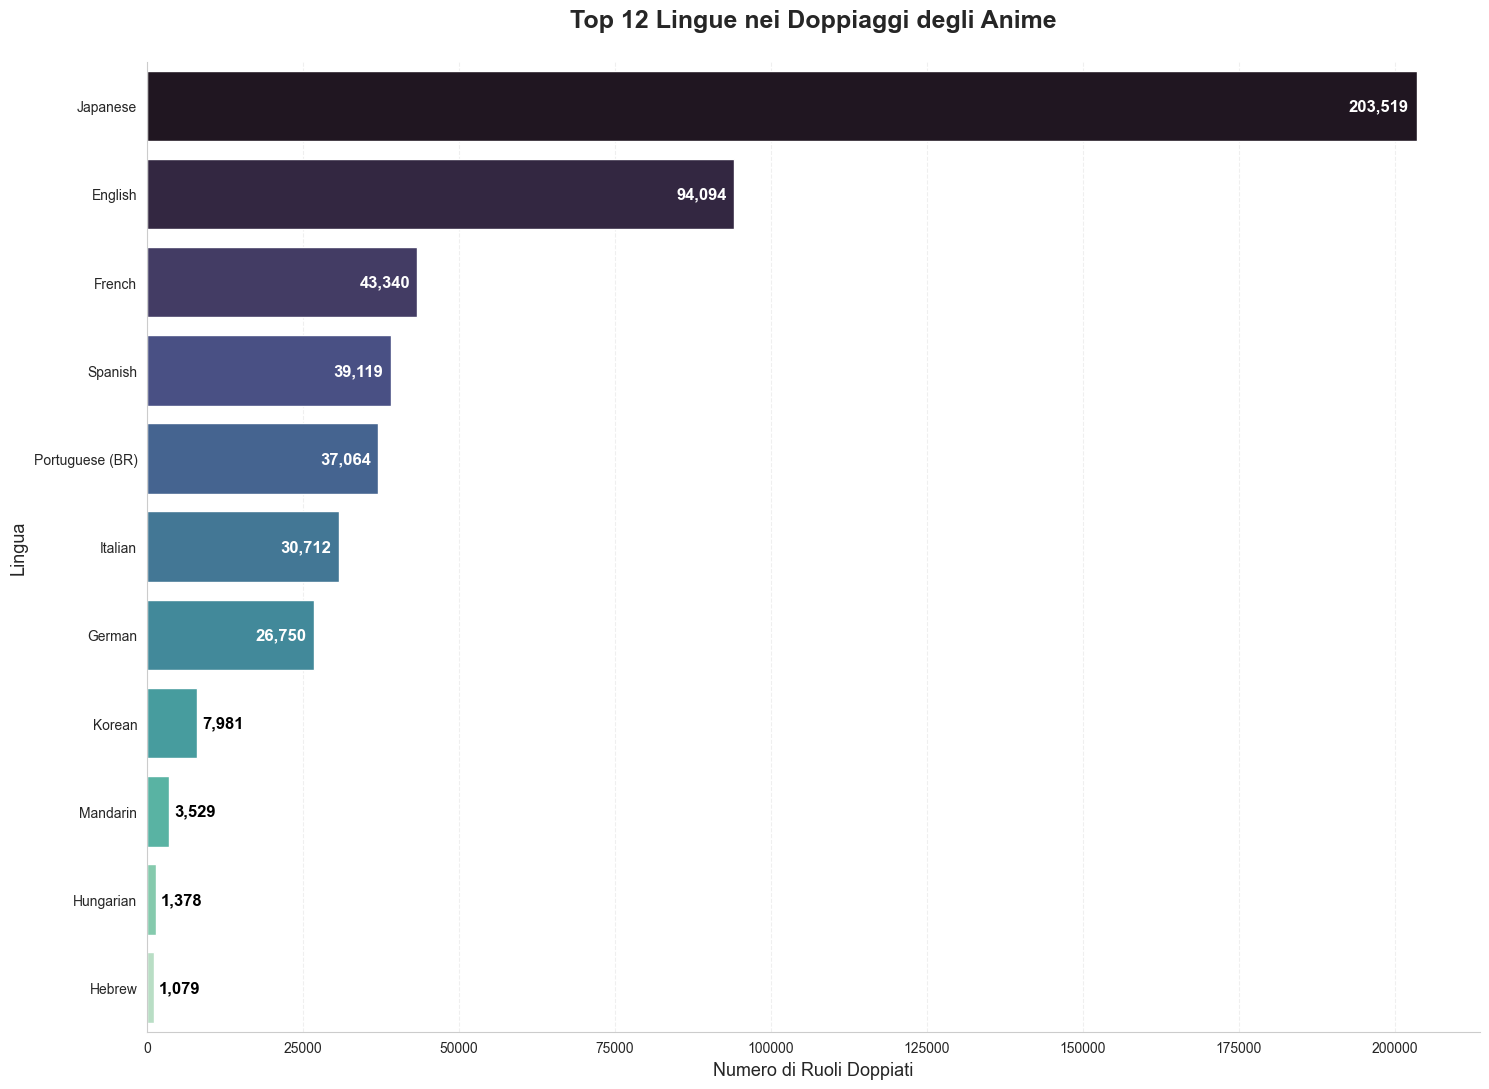

In [18]:
voice = df_person_voice_works.copy()

# Preparazione dati
lang_stats = voice.groupby('language').agg(total_roles=('character_mal_id', 'count')).sort_values('total_roles', ascending=False)
# Top 12 lingue
top12 = lang_stats.head(12).reset_index()
plt.figure(figsize=(15, 11))
sns.set_style("whitegrid")
ax = sns.barplot(data=top12,y='language',x='total_roles',palette='mako')
plt.title('Top 12 Lingue nei Doppiaggi degli Anime',fontsize=18,fontweight='bold',pad=25)
plt.xlabel('Numero di Ruoli Doppiati', fontsize=13)
plt.ylabel('Lingua', fontsize=13)

for i, row in enumerate(top12.itertuples()):

    if row.total_roles > 10000:
        # Per barre lunghe
        ax.text(x = row.total_roles - 1200,y = i, s = f"{row.total_roles:,}",
            va = 'center',ha = 'right',fontsize = 12,color = 'white',fontweight = 'bold'
        )
    else:
        # Per barre corte
        ax.text(x = row.total_roles + 800,y = i,s = f"{row.total_roles:,}",
            va = 'center',ha = 'left',fontsize = 12,color = 'black',fontweight = 'bold'
        )

# Stile pulito
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

## 7. Community anime nel mondo

In [19]:
profiles = df_profiles.copy()

# estrazione del paese
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# conversione in ISO3
profiles["iso3"] = profiles["country"].apply(utils.to_iso3)

# controlli
u_total = profiles["username"].nunique()
u_loc = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_iso = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

print(f"Unique users: {u_total:,}")
print(f"Users with location: {u_loc:,} ({u_loc/u_total:.1%})")
print(f"Users mapped to ISO3: {u_iso:,} ({u_iso/u_total:.1%} of total)")
print(f"Coverage among users with location: {u_iso/u_loc:.1%}")

# conteggio utenti unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
    .groupby("iso3")["username"]
    .nunique()
    .reset_index(name="n_users")
)

country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Where is the anime community concentrated?",
    color_continuous_scale=px.colors.sequential.Plasma
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_coloraxes(
    colorbar_title=dict(text="log10(users)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="lightgrey",
    showocean=True,
    oceancolor="#e6f2ff"
)

fig.show()

La mappa evidenzia paesi in cui il dataset registra una maggiore presenza di utenti appassionati di anime. L'intensità del colore cresce all'aumentare del numero di utenti unici per paese; l'uso della trasformazione log(n_users + 1) comprime le differenze estreme di valore e rende visibili anche paesi con valori più bassi.

#### A questo punto possiamo vedere come l'interesse per gli anime si è sviluppato durante il corso del tempo, considerando i paesi dove esse son maggiormente diffuse.

## I principali poli geografici della community anime

In [20]:
top6_counts = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).reset_index(name="n_users")
)
fig = px.bar( top6_counts, x="country", y="n_users", text="n_users", title="Main geographic hubs of the anime community", labels={"country": "Country", "n_users": "Unique users"}
)
fig.update_traces(textposition="outside")
fig.update_layout(
    width=900, height=500
)
fig.update_yaxes(tickformat=".2s")
fig.update_xaxes(categoryorder="total descending")

fig.show()

La community risulta fortemente concentrata in pochi paesi: Giappone e Stati Uniti emergono come i poli principali, seguiti da un secondo gruppo con valori molto più contenuti.

## Crescita nella community nel tempo

In [21]:
profiles = df_profiles.copy()
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles = profiles.dropna(subset=["joined_year", "country"])
top_countries = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).index
)

trend = (
    profiles.loc[
        profiles["country"].isin(top_countries) & profiles["joined_year"].between(2005, 2024)
    ].groupby(["joined_year", "country"])["username"].nunique().reset_index(name="n_users")
)

fig = px.line(
    trend, x="joined_year", y="n_users", color="country", markers=True, title="Anime Community Growth in the Main Countries",
    labels={
        "joined_year": "Year", "n_users": "New Users", "country": "Country"
    }
)
fig.update_layout(
    width=900, height=500
)

fig.show()

Il grafico mostra l'andamento dei nuovi utenti registrati ogni anno nei 6 paesi con la maggiore concentrazione di utenti nel dataset. Il Giappone e gli Stati Uniti offrono contributo dominante, mentre gli altri paesi hanno volumi più contenuti ma comunque trend simili.

#### E l'evoluzione a livello globale? Vediamo come si modifica a livello temporale ...

## Crescita della community nel tempo a livello globale

In [22]:
df = df_profiles.copy()
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year
users_per_year = (
    df.dropna(subset=["joined_year"]).groupby("joined_year")["username"].nunique().reset_index(name="new_users")
)
users_per_year["joined_year"] = users_per_year["joined_year"].astype(int)
users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)]
fig = px.line(
    users_per_year, x="joined_year", y="new_users", markers=True, title="Nuovi utenti registrati per anno",
    labels={
        "joined_year": "Anno", "new_users": "Nuovi utenti"
    }
)
fig.add_vrect(x0=2008, x1=2009, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_vrect(x0=2020, x1=2022, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_annotation(
    x=2008.5, y=users_per_year["new_users"].max() * 0.95, text="Crisi finanziaria", showarrow=False
)
fig.add_annotation(
    x=2021, y=users_per_year["new_users"].max() * 0.95, text="Pandemia COVID-19", showarrow=False
)
fig.update_layout(
    width=850, height=450
)
fig.show()

Il grafico mostra l’andamento dei nuovi utenti registrati ogni anno: si osserva una crescita nel tempo, con picchi marcati negli anni più recenti.

## Distribuzione del genere dichiarato dall'utente

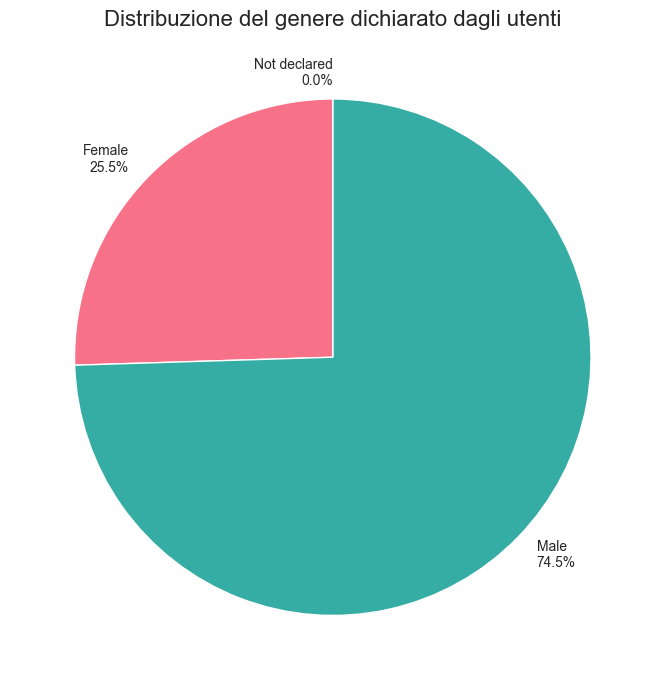

In [23]:
gender_counts = (
    profiles["gender"].value_counts().reindex(["Female", "Male", "Not declared"], fill_value=0).rename_axis("gender").reset_index(name="count")
)
gender_counts["percentage"] = (
    gender_counts["count"] / gender_counts["count"].sum() * 100
).round(1)
gender_counts
palette = sns.color_palette("husl", len(top_anime_voice))
plt.style.use("default")
sns.set_style("white")
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
labels = gender_counts["gender"] + "\n" + gender_counts["percentage"].astype(str) + "%"
ax.pie(
    gender_counts["count"], labels=labels, colors=colors, startangle=90
)
ax.set_title("Distribuzione del genere dichiarato dagli utenti", fontsize=16)
plt.tight_layout()
plt.show()

Nel grafico viene mostrata la quota più ampia che è rappresentata dagli utenti che non hanno dichiarato il loro genere, mentre tra i profili che hanno compilato il campo prevalgono quelli maschili rispetto a quelli femminili.

## 8. PERSONE E RUOLI NELL'INDUSTRIA ANIME

## Da quali paesi provengono le persone che lavorano nell'industria anime

In [24]:
country_counts = df_person_details.copy()
country_counts["country"] = (
    country_counts["relevant_location"]
    .astype("string")
    .str.split(",")
    .str[-1]
    .str.strip()
)
country_counts["country"] = country_counts["country"].replace(utils.COUNTRY_FIX)
country_counts = (
    country_counts.groupby("country")["person_mal_id"]
    .nunique()
    .reset_index(name="n_people")
)
country_counts["iso3"] = country_counts["country"].apply(utils.to_iso3)
present_df = country_counts.dropna(subset=["iso3"]).copy()

fig = px.choropleth(
    present_df,
    locations="iso3",
    color="n_people",
    hover_name="country",
    title="Countries with at Least One Person in the Credits",
    color_continuous_scale=["#dff5ef", "#7fd6c2"]
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="white",
    showcountries=True,
    countrycolor="lightgrey",
    showocean=True,
    oceancolor="#f5f7fb",
    showframe=False
)

fig.show()

Il grafico mostra la distribuzione geografica delle persone accreditate nei credits anime.
La mappa evidenzia i paesi in cui è presente almeno una persona, mentre il bar chart quantifica il numero di persone uniche per paese, mostrando una forte concentrazione in pochi poli principali.


## Distribuzione Generazionale delle persone che lavorano nell'industria anime

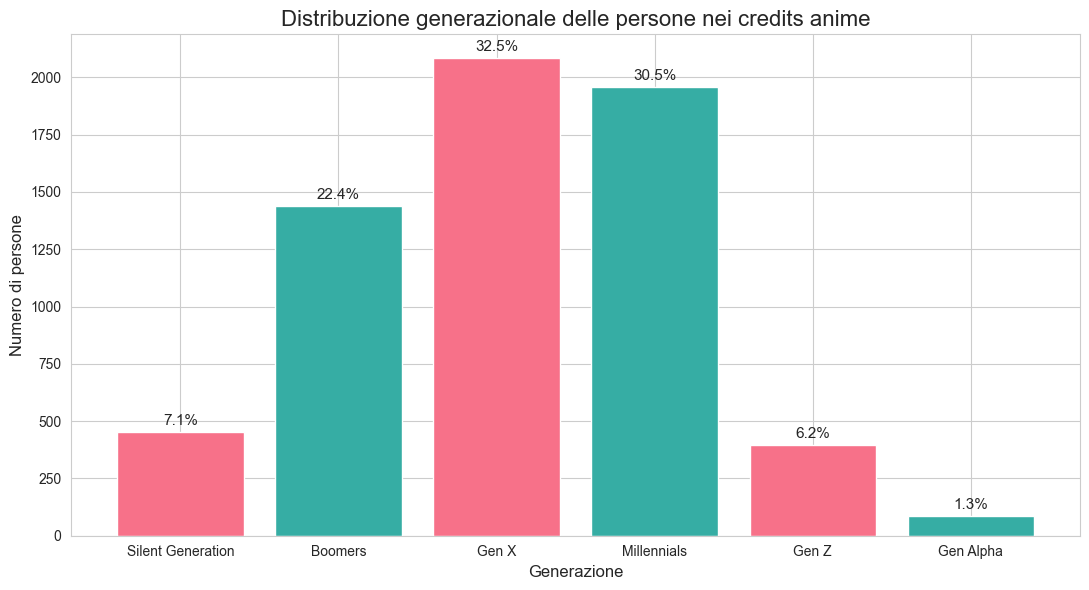

In [25]:
staff = df_person_anime_works[["person_mal_id"]].drop_duplicates().merge(df_person_details[["person_mal_id", "birthday"]], on="person_mal_id", how="left")

staff["birth_year"] = pd.to_datetime(staff["birthday"], errors="coerce", utc=True).dt.year
staff.loc[~staff["birth_year"].between(1900, 2024), "birth_year"] = pd.NA
tot_people = staff["person_mal_id"].nunique()
known_people = staff.loc[staff["birth_year"].notna(), "person_mal_id"].nunique()
labels = ["Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"]
staff["generation"] = pd.cut(staff["birth_year"], bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024], labels=labels)
gen_counts = staff["generation"].value_counts().reindex(labels, fill_value=0).rename_axis("generation").reset_index(name="count")
gen_counts["share"] = (gen_counts["count"] / gen_counts["count"].sum() * 100).round(1)
palette = sns.color_palette("husl", len(top_anime_voice))
plt.style.use("default")
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.bar(gen_counts["generation"], gen_counts["count"], color=colors)
ax.set_title("Distribuzione generazionale delle persone nei credits anime", fontsize=16)
ax.set_xlabel("Generazione", fontsize=12)
ax.set_ylabel("Numero di persone", fontsize=12)
labels_bar = gen_counts["share"].astype(str) + "%"
ax.bar_label(bars, labels=labels_bar, padding=3, fontsize=11)
plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione delle generazioni tra le persone presenti nello staff, ogni barra evidenzia il numero di persone uniche per generazione, con la percentuale calcolata sul sottoinsieme per cui l'anno di nascita è disponibile.


## Ruoli più frequenti e notorietà nell'industria anime

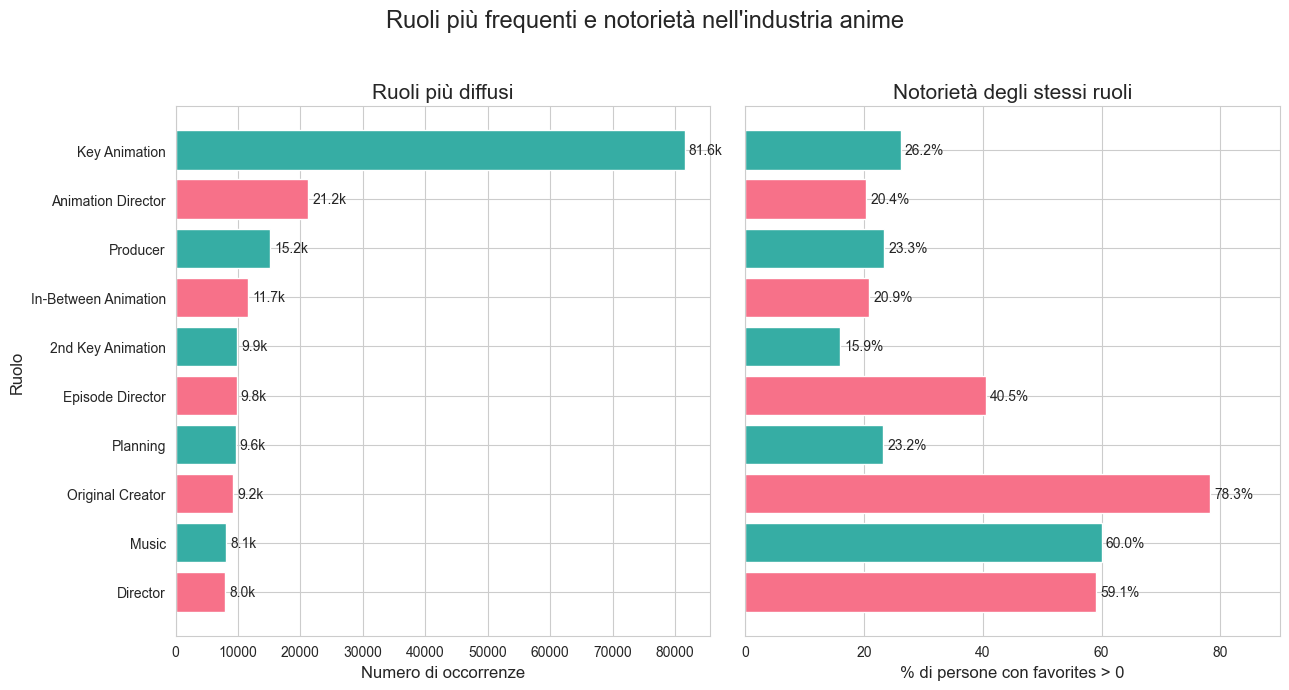

In [26]:
top10 = df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().value_counts().head(10).rename_axis("role").reset_index(name="occurrences")

role_people = df_person_anime_works.loc[
    df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().isin(top10["role"]), ["person_mal_id", "position"]
].copy()
role_people["role"] = role_people["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip()
role_people = role_people.drop_duplicates(subset=["person_mal_id", "role"])
role_people = role_people.merge(df_person_details[["person_mal_id", "favorites"]], on="person_mal_id", how="left")
fav_stats = role_people.groupby("role")["favorites"].agg(share_nonzero=lambda x: (x.fillna(0) > 0).mean() * 100).reset_index()

top10 = top10.merge(fav_stats, on="role", how="left").sort_values("occurrences", ascending=True)

palette = sns.color_palette("husl", len(top_anime_voice))

plt.style.use("default")
sns.set_style("whitegrid")

fig, ax = plt.subplots(1, 2, figsize=(13, 7), sharey=True, facecolor="white")
fig.patch.set_facecolor("white")

bars1 = ax[0].barh(top10["role"], top10["occurrences"], color=colors)
bars2 = ax[1].barh(top10["role"], top10["share_nonzero"], color=colors)

ax[0].set_title("Ruoli più diffusi", fontsize=15)
ax[1].set_title("Notorietà degli stessi ruoli", fontsize=15)

ax[0].set_xlabel("Numero di occorrenze", fontsize=12)
ax[1].set_xlabel("% di persone con favorites > 0", fontsize=12)
ax[0].set_ylabel("Ruolo", fontsize=12)

labels_occ = (top10["occurrences"] / 1000).round(1).astype(str) + "k"
labels_fav = top10["share_nonzero"].round(1).astype(str) + "%"

ax[0].bar_label(bars1, labels=labels_occ, padding=3, fontsize=10)
ax[1].bar_label(bars2, labels=labels_fav, padding=3, fontsize=10)

ax[1].set_xlim(0, top10["share_nonzero"].max() * 1.15)

fig.suptitle("Ruoli più frequenti e notorietà nell'industria anime", fontsize=17)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

I due grafici confrontano, per gli stessi 10 ruoli più frequenti nei credits anime, la loro diffusione e la quota di persone associate che risultano selezionate almeno una volta tra i favorites. In questo modo è possibile distinguere i ruoli più presenti nei credits da quelli che risultano anche più riconoscibili.

## 9. COME GLI UTENTI SEGUONO GLI ANIME

## Stato di visione degli anime e come varia nel tempo

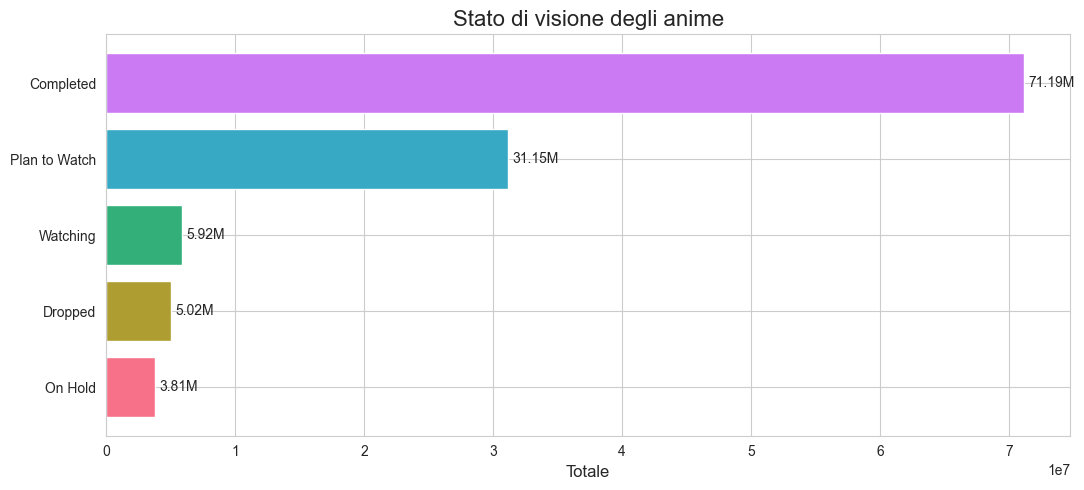

In [27]:
profiles = df_profiles.copy()

cols = ["watching", "completed", "on_hold", "dropped", "plan_to_watch"]
profiles[cols] = profiles[cols].fillna(0)

status_labels = {
    "watching": "Watching",
    "completed": "Completed",
    "on_hold": "On Hold",
    "dropped": "Dropped",
    "plan_to_watch": "Plan to Watch"
}

status_totals = profiles[cols].sum().rename_axis("status").reset_index(name="total")
status_totals["status"] = status_totals["status"].replace(status_labels)
status_totals = status_totals.sort_values("total")

palette = sns.color_palette("husl", len(status_totals))

plt.figure(figsize=(11, 5))
ax = plt.gca()

bars = ax.barh(
    status_totals["status"],
    status_totals["total"],
    color=palette
)

ax.set_title("Stato di visione degli anime", fontsize=16)
ax.set_xlabel("Totale", fontsize=12)
ax.set_ylabel("")

labels_bar = (status_totals["total"] / 1000000).round(2).astype(str) + "M"
ax.bar_label(bars, labels=labels_bar, padding=3, fontsize=10)

plt.tight_layout()
plt.show()

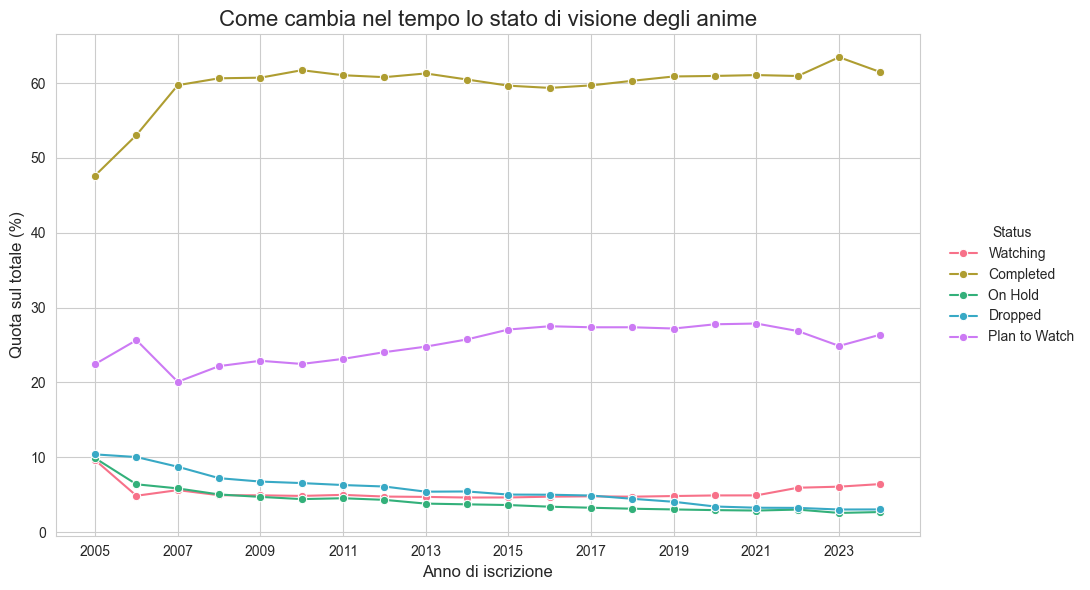

In [28]:
profiles = df_profiles.copy()

profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

cols = ["watching", "completed", "on_hold", "dropped", "plan_to_watch"]
profiles[cols] = profiles[cols].fillna(0)

profiles = profiles.dropna(subset=["joined_year"])
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2005, 2024)]

status_order = ["Watching", "Completed", "On Hold", "Dropped", "Plan to Watch"]
status_palette = dict(zip(status_order, sns.color_palette("husl", len(status_order))))

cohort_totals = profiles.groupby("joined_year")[cols].sum().reset_index()
den = cohort_totals[cols].sum(axis=1)
cohort_pct = cohort_totals.loc[den > 0].copy()
cohort_pct[cols] = cohort_pct[cols].div(cohort_pct[cols].sum(axis=1), axis=0) * 100

cohort_long = cohort_pct.melt(id_vars="joined_year", value_vars=cols, var_name="status", value_name="share")
cohort_long["status"] = cohort_long["status"].replace(status_labels)

plt.figure(figsize=(11,6))
ax = plt.gca()

sns.lineplot(data=cohort_long, x="joined_year", y="share", hue="status", palette=status_palette, marker="o", ax=ax)

ax.set_title("Come cambia nel tempo lo stato di visione degli anime", fontsize=16)
ax.set_xlabel("Anno di iscrizione", fontsize=12)
ax.set_ylabel("Quota sul totale (%)", fontsize=12)
ax.set_xticks(cohort_pct["joined_year"][::2])
ax.set_xticklabels(cohort_pct["joined_year"][::2].astype(int))
ax.legend(title="Status", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.tight_layout()
plt.show()

Il primo grafico riassume la distribuzione complessiva degli status delle liste anime, mostrando una netta prevalenza di “Completed” e, in secondo luogo, di “Plan to Watch”.

Il secondo grafico confronta la composizione relativa degli status tra utenti iscritti in anni diversi, così da osservare come cambiano le liste senza che la diversa dimensione delle coorti condizioni il confronto.

## 10. TARGET DEMOGRAFICI E PUBBLICO PREVISTO

### Distribuzione delle demografiche

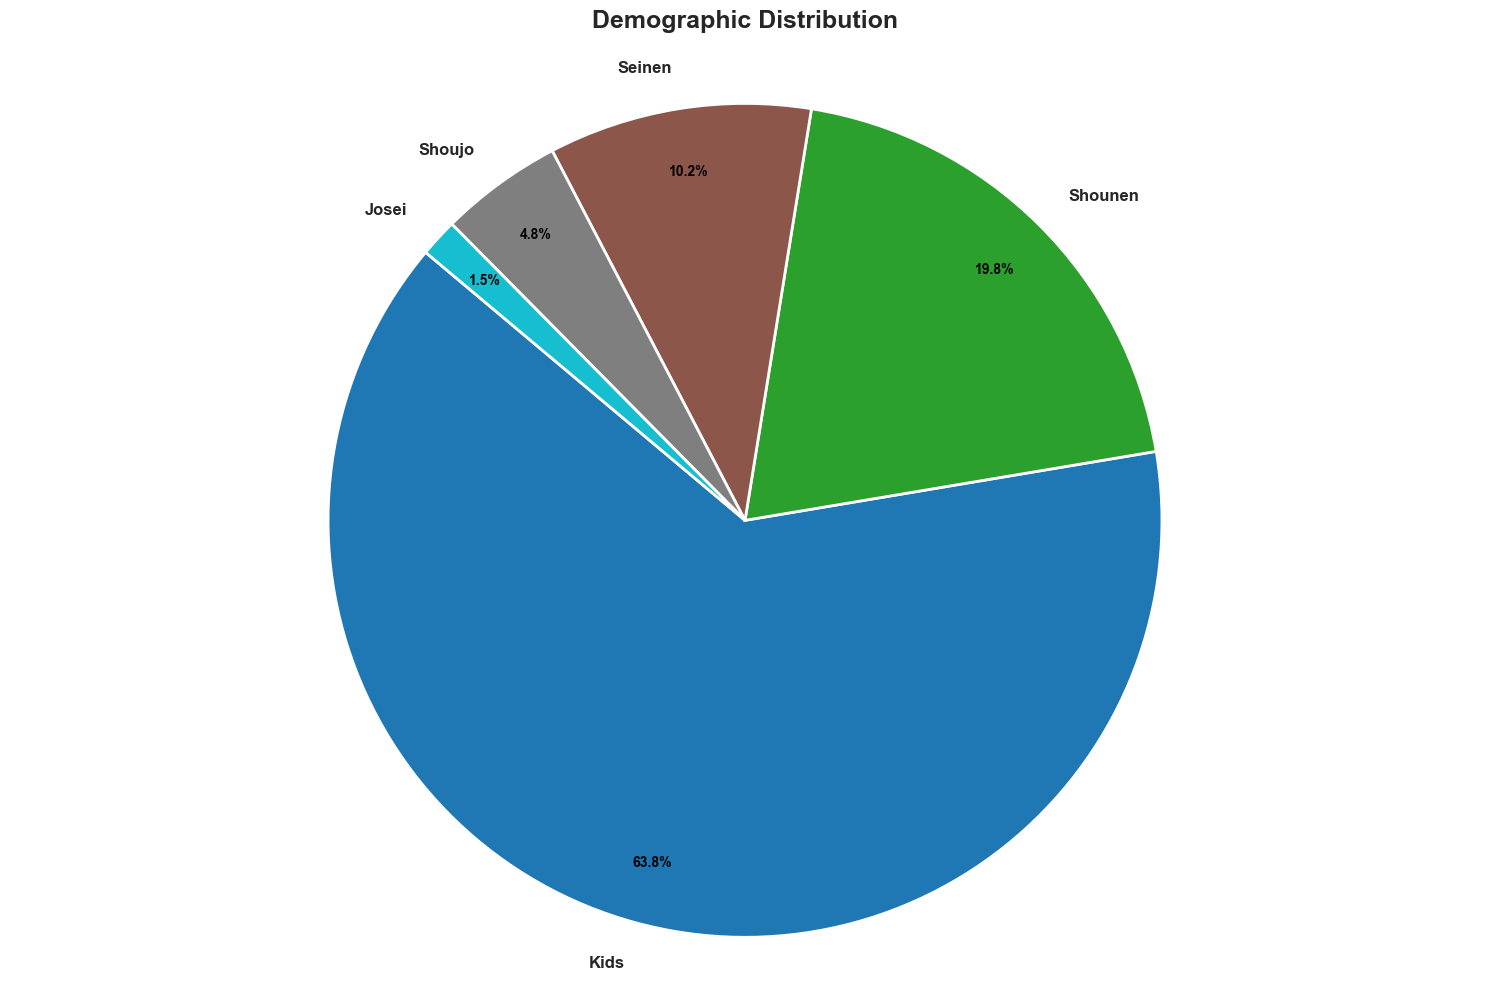

In [29]:
details_copy = df_details.copy()
details_copy = details_copy['demographics'].apply(eval).explode()

demographic_count = details_copy.value_counts()
n = len(demographic_count)
colors = plt.cm.tab10.resampled(n)(range(n))

# Pie chart
fig, ax = plt.subplots(figsize=(15, 10))
wedges, texts, autotexts = ax.pie(
    demographic_count.values,
    labels=demographic_count.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    pctdistance=0.85,
    textprops={'fontsize': 11}
)
# Miglioramenti estetici
plt.setp(autotexts, size=10, weight="bold", color="black")
plt.setp(texts, size=12, weight="bold")

ax.set_title('Demographic Distribution', fontsize=18, pad=25, fontweight='bold')

plt.axis('equal')
plt.tight_layout()
plt.show()

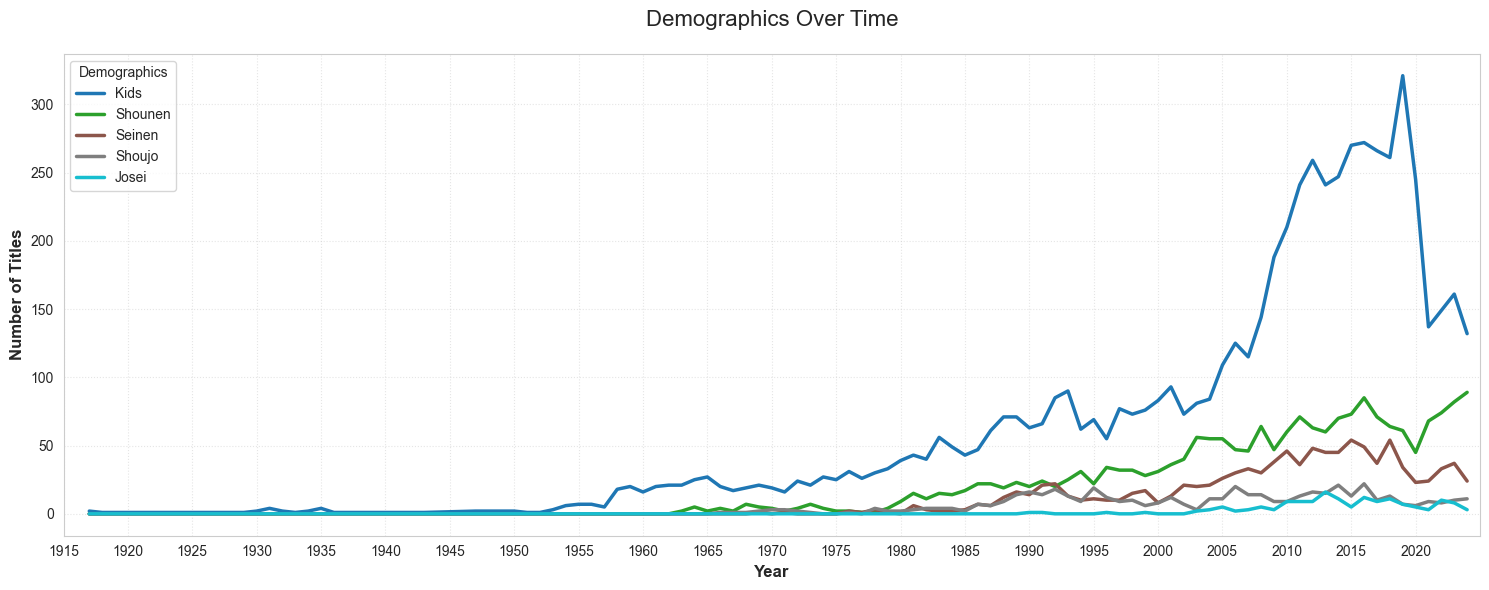

In [30]:
details_copy = df_details.copy()
details_copy = details_copy[details_copy['year'] < 2025].copy()
details_copy['demographics'] = details_copy['demographics'].apply(eval)
details_copy = details_copy.explode('demographics')
# conteggio per anno
counts = details_copy.groupby(['year', 'demographics']).size().unstack(fill_value=0).sort_index()
freq_order = details_copy['demographics'].value_counts().index
counts = counts[freq_order]
n_colors = len(counts.columns)
palette = plt.cm.tab10.resampled(n)(range(n_colors))
# creazione grafico
plt.figure(figsize=(15,6))
plt.grid(linestyle=':', alpha=0.5)
counts.plot(kind='line', ax=plt.gca(), linewidth=2.5, color=palette)
# personalizzazione assi
plt.title(f'Demographics Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.legend(title='Demographics', loc='upper left', frameon=True)
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2024, 5))

plt.tight_layout()
plt.show()


## 11. CONCLUSIONE - GLI ANIME COME ECOSISTEMA CULTURALE E GLOBALE